In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
dataset=pd.read_csv("50_Startups.csv")

In [3]:
dataset=(pd.get_dummies(dataset,drop_first=True,dtype=int))

In [4]:
dataset.columns

Index(['R&D Spend', 'Administration', 'Marketing Spend', 'Profit',
       'State_Florida', 'State_New York'],
      dtype='object')

In [5]:
independent =dataset[['R&D Spend', 'Administration', 'Marketing Spend', 'State_Florida', 'State_New York']]
dependent = dataset[['Profit']]

In [6]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split( independent, dependent, test_size=0.30, random_state=0)

In [7]:
from sklearn.preprocessing import StandardScaler #standarizing the value if we have abnormal variance
sc=StandardScaler()
X_train=sc.fit_transform(X_train) #Mean value and Standard deviation Value got calculated
X_test=sc.transform(X_test)

In [8]:
from sklearn.linear_model import QuantileRegressor
regressor = QuantileRegressor(quantile=0.50, alpha=1.0, fit_intercept=True, solver='highs') #Passing Hyper Tuning Parameters to evaluate performance/Model improvement
regressor = QuantileRegressor(quantile=0.50).fit(X_train,y_train)
# Link - https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.QuantileRegressor.html
# Quantile Regression Expaination - https://www.google.com/search?q=what+is+mean+by+pin+ball+loss+in+quantile+regression+model&sca_esv=34651f0857a3a838&sxsrf=APpeQnuhr17_26KEAP5dvO_lEVEZaHD-tg%3A1792514427574&source=hp&ei=e5nXapGqIYWxwcsP5IPYiAo&iflsig=ABILxe8AAAAAateni3Jc8gN9w803hWlViu65yojYQujE&oq=what+is+mean+by+pin+ball+loss+in+Quantile+regression&gs_lp=Egdnd3Mtd2l6IjR3aGF0IGlzIG1lYW4gYnkgcGluIGJhbGwgbG9zcyBpbiBRdWFudGlsZSByZWdyZXNzaW9uKgcIARgKGKABMgcQIRgKGKABMgcQIRgKGKABSOGKAVAAWLRxcAB4AJABAJgBsgGgAd0sqgEFMTkuMzO4AQPIAQD4AQGYAjSgApgvwgIIEAAYgAQYtAfCAggQABiABBixA8ICERAuGIAEGLEDGIMBGMcBGNEDwgILEAAYgAQYsQMYgwHCAgUQABiABMICCxAuGIAEGLEDGIMBwgIOEAAYgAQYigUYjQYYsQPCAhEQABiABBiKBRixAxiDARi0B8ICDhAAGIAEGIoFGLEDGIMBwgIGEAAYFhgewgILEAAYgAQYigUYhgPCAggQABiABBiiBMICBRAAGO8FwgIEECEYFZgDAJIHBTE2LjM2oAfBkgKyBwUxNi4zNrgHmC_CBwk0LjI4LjE3LjPIB6UBgAgB&sclient=gws-wiz


C:\Anaconda3\Lib\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [9]:
y_pred = regressor.predict(X_test) #Predicting the test data

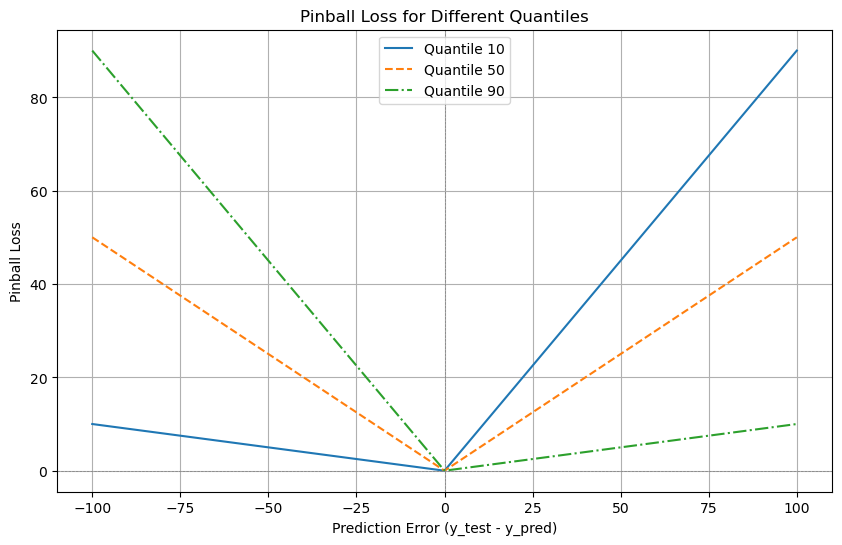

In [12]:
## Evaluates the loss based on whether the model under-predicts or over-predicts
def pinball_loss(y_test, y_pred, quantile):
    return np.where(
        y_test >= y_pred, 
        quantile * (y_test - y_pred), 
        (quantile - 1) * (y_test - y_pred)
    )
errors = np.linspace(-100, 100, 400)
y_test = errors
y_pred = 0
quantiles = [0.1, 0.5, 0.9]
line_styles = ['-', '--', '-.']
plt.figure(figsize=(10, 6))
for q, ls in zip(quantiles, line_styles):
    losses = pinball_loss(y_test, y_pred, q)
    plt.plot(errors, losses, linestyle=ls, label=f'Quantile {q*100:.0f}')
plt.axhline(0, color='gray', linestyle='--', linewidth=0.5)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.5)
plt.xlabel('Prediction Error (y_test - y_pred)')
plt.ylabel('Pinball Loss')
plt.title('Pinball Loss for Different Quantiles')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import r2_score #Calculating r_score value
r_score=r2_score(y_test,y_pred)

In [ ]:
r_score